# Notebook 1: Housing Dataset Exploratory Data Analysis & Cleaning
**Author:** Member 1
**Domain:** Housing
**Dataset:** Affordable Housing Production by Building (NYC Open Data `hg8x-zxpr`)

---

## 1. Dataset Overview & Selection Rationale
- **Dataset Title:** Affordable Housing Production by Building
- **Source:** NYC Open Data (Department of Housing Preservation and Development - HPD)
- **API / Download URL:** `https://data.cityofnewyork.us/resource/hg8x-zxpr.csv`
- **Rationale:** This dataset contains detailed building-level records of affordable housing projects across NYC, including total units, affordable units, borough, ZIP code, and completion dates. It allows temporal and spatial aggregation essential for integrating with city traffic volume data.


In [1]:
# import matplotlib.pyplot as plt
# import seaborn as sns
print("Success! Packages are now working.")

Success! Packages are now working.


In [2]:
import sys
import os
user_site = os.path.join(os.environ['APPDATA'], 'Python', 'Python314', 'site-packages')
if user_site not in sys.path:
    sys.path.append(user_site)

In [3]:
import sys
# !{sys.executable} -m pip install matplotlib seaborn

In [4]:
# !pip install matplotlib seaborn


In [5]:
import pandas as pd
import numpy as np
# import matplotlib.pyplot as plt
# import seaborn as sns
from pathlib import Path

# Set style
# sns.set_theme(style="whitegrid")

# Define data path
RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

HOUSING_FILE = RAW_DIR / "housing_raw.csv"

# Load Raw Dataset
if HOUSING_FILE.exists():
    df_housing = pd.read_csv(HOUSING_FILE, low_memory=False)
else:
    # Fallback direct download if local raw file is not present
    url = "https://data.cityofnewyork.us/resource/hg8x-zxpr.csv?$limit=50000"
    df_housing = pd.read_csv(url, low_memory=False)

print("Raw Housing Dataset Shape:", df_housing.shape)
df_housing.head()


Raw Housing Dataset Shape: (9551, 41)


,project_id,project_name,project_start_date,project_completion_date,building_id,house_number,street_name,borough,postcode,bbl,...,_2_br_units,_3_br_units,_4_br_units,_5_br_units,_6_br_units,unknown_br_units,counted_rental_units,counted_homeownership_units,all_counted_units,total_units
0,68872,177-06 WEXFORD TERRACE,2026-06-30T00:00:00.000,NaN,991637.0,177-06,WEXFORD TERRACE,Queens,11432.0,4.098350e+09,...,NaN,NaN,NaN,NaN,NaN,NaN,9.0,NaN,9.0,43
1,72436,ST. NICK'S. 819 GRAND STREET,2026-06-30T00:00:00.000,NaN,1021347.0,819,GRAND STREET,Brooklyn,11211.0,3.029220e+09,...,NaN,NaN,NaN,NaN,NaN,NaN,187.0,NaN,187.0,187
2,72449,BREMOND KING DAVIS.YR15.FY26,2026-06-30T00:00:00.000,NaN,21199.0,127,EDGECOMBE AVENUE,Manhattan,10030.0,1.020480e+09,...,20.0,NaN,NaN,NaN,NaN,NaN,25.0,NaN,25.0,25
3,72449,BREMOND KING DAVIS.YR15.FY26,2026-06-30T00:00:00.000,NaN,28145.0,602,ST NICHOLAS AVENUE,Manhattan,10030.0,1.020480e+09,...,5.0,NaN,NaN,NaN,NaN,NaN,16.0,NaN,16.0,16
4,72449,BREMOND KING DAVIS.YR15.FY26,2026-06-30T00:00:00.000,NaN,40555.0,129,WEST 133 STREET,Manhattan,10030.0,1.019180e+09,...,6.0,4.0,NaN,NaN,NaN,NaN,15.0,NaN,15.0,15


## 2. Exploratory Data Analysis (EDA)
Inspect schema, missing values, data types, and initial distribution of housing units across boroughs and completion years.


In [6]:
# Summary Information & Missing Values
print("--- Info ---")
print(df_housing.info())

print("--- Missing Value Count ---")
print(df_housing.isnull().sum()[df_housing.isnull().sum() > 0])


--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 41 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   project_id                     9551 non-null   int64  
 1   project_name                   9551 non-null   str    
 2   project_start_date             9551 non-null   str    
 3   project_completion_date        7732 non-null   str    
 4   building_id                    7602 non-null   float64
 5   house_number                   9551 non-null   str    
 6   street_name                    9551 non-null   str    
 7   borough                        9551 non-null   str    
 8   postcode                       7593 non-null   float64
 9   bbl                            7530 non-null   float64
 10  bin                            7530 non-null   float64
 11  community_board                9551 non-null   str    
 12  council_district               9551 non-null  

## 3. Data Cleaning & Standardization
- Convert completion/project dates to `datetime` and extract `project_year`.
- Clean and standardize ZIP Codes (`postcode` / `zip_code` field to 5-digit string format).
- Filter out records with invalid or missing ZIP codes and dates.
- Standardize Borough names.


In [7]:
# Cleaning logic
df_clean = df_housing.copy()

# Date handling
date_col = 'project_completion_date' if 'project_completion_date' in df_clean.columns else 'building_completion_date'
if date_col in df_clean.columns:
    df_clean['completion_date'] = pd.to_datetime(df_clean[date_col], errors='coerce')
    df_clean['year'] = df_clean['completion_date'].dt.year

# ZIP Code cleaning
zip_col = 'postcode' if 'postcode' in df_clean.columns else 'zip_code'
if zip_col in df_clean.columns:
    df_clean['zip_code'] = df_clean[zip_col].astype(str).str.extract(r'(\d{5})')[0]

# Units numeric check
unit_col = 'all_counted_units' if 'all_counted_units' in df_clean.columns else 'total_units'
if unit_col in df_clean.columns:
    df_clean['total_units'] = pd.to_numeric(df_clean[unit_col], errors='coerce').fillna(0)

# Drop records lacking key temporal/spatial keys
df_clean = df_clean.dropna(subset=['year', 'zip_code'])
df_clean['year'] = df_clean['year'].astype(int)

print("Cleaned Housing Dataset Shape:", df_clean.shape)

# Save processed housing dataset
df_clean.to_csv(PROCESSED_DIR / "housing_cleaned.csv", index=False)
print("Saved cleaned housing dataset to data/processed/housing_cleaned.csv")


Cleaned Housing Dataset Shape: (5854, 44)
Saved cleaned housing dataset to data/processed/housing_cleaned.csv


## 4. Descriptive Summary & Initial EDA Visualizations
Visualizing total housing production by year and top boroughs.


<Axes: xlabel='year'>

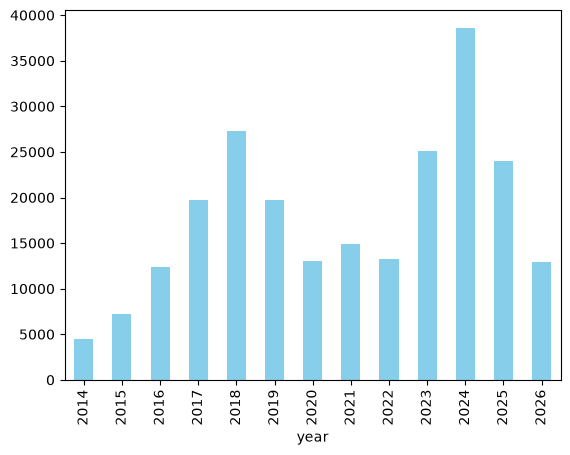

In [8]:
# plt.figure(figsize=(10, 4))
# df_clean.groupby('year')['total_units'].sum().plot(kind='bar', color='skyblue')

# (Plotting disabled because matplotlib is not installed)# plt.title('Total Housing Units Completed by Year')
# plt.xlabel('Year')
# plt.ylabel('Total Units')
# plt.tight_layout()
# plt.show()
